<a href="https://colab.research.google.com/github/LucioFassarella/AMC/blob/main/SQC_qubit_amplitude-dampping.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Quantum Simulation of Markovian Quantum Systems

$$
\text{Summary of the quantum simulation protocol}
$$

$$
\
$$

$$
\text{Lindblad's Equation}
$$
\begin{align}
\frac{d}{dt}\rho = \mathcal{L}(\rho),\ \mathcal{L}(\cdot) = -\frac{i}{\hbar} (H, \cdot ) + \sum_{k=1}^m \gamma_j(L_j (\cdot) L_j^\dagger - \frac{1}{2}\{L_j^\dagger L_j, \cdot\})
\end{align}

$$
\Downarrow
$$

$$
\text{Infinitesimal time evolution}
$$

\begin{align}
\rho(t+dt) = \rho(t) + \mathcal{L}(\rho(t))dt + O(dt^2)
\end{align}

$$
\Downarrow
$$

\begin{align}
\text{Infinitesimal Kraus operators}
\end{align}

\begin{align}
K_0 = I + L_0dt - L_0L_0^\dagger dt^2;\ K_j = \sqrt{\gamma_j dt}L_j,\ L_0 = -i\hbar H -\frac{1}{2}\sum_{j=1}^m\gamma_j L_j^\dagger L_j
\end{align}

$$
\text{Stinespring dilation}
$$

\begin{align}
V(\cdot) = \sum_{j=0}^m K_j(\cdot) \otimes \vert j\rangle
\end{align}

$$
\Downarrow
$$

$$
\text{Stinespring unitary}
$$

\begin{align}
W(\vert \ell \rangle \otimes \vert j\rangle) = \vert \phi_{k,j} \rangle,\ \vert \phi_{\ell,0} \rangle = V\vert \ell\rangle = \sum_{j=0}^m (K_j \vert \ell\rangle) \otimes \vert j\rangle
\end{align}

$$
\Downarrow
$$

$$
\text{Finite time evolution}
$$

\begin{align}
\begin{array}{ll}
		\rho(t + qdt) &%
		=tr_{\mathcal{G}}(W\dots tr_{\mathcal{G}}(Wtr_\mathcal{G}(W (\vert \psi\rangle\langle \psi \vert\otimes \vert 0\rangle\langle 0 \vert)W^\dagger)W^\dagger) \dots W^\dagger),\ \forall q \in \mathbb{N}.
	\end{array}
\end{align}

## Amplitude Damping Qubit

**Hilbert Space and Lindblad Equation**:
$$
\mathcal{H} = \mathbb{C}^2 = \mathrm{spam}\{\vert 0 \rangle, \vert 1 \rangle\},
$$
$$
\frac{d}{dt}\rho = -i\epsilon \left[H,\rho\right] + \gamma\left(\sigma^+\rho \sigma^- - \frac{1}{2}\{\sigma^-\sigma^+,\rho\}\right),
$$
where
$$
\sigma^+ := \vert0\rangle\langle 1 \vert,\ \sigma^-  :=\vert 1\rangle\langle 0 \vert.
$$
**Hamiltonian and Lindblad operators**:
$$
H =  -\epsilon Z
$$
$$
\begin{split}
L_1 &:= \sigma^+,\\
L_0 &:= - \frac{\gamma}{2} L_1^\dagger L_1 + i\epsilon Z = - \frac{\gamma}{2}\vert 1\rangle\langle 1 \vert - i\frac{\epsilon}{\hbar} Z.
\end{split}
$$

**General solution of the Lindblad equation**

$$
\rho(t) = \begin{pmatrix}
1 - e^{-\gamma t}a & e^{(2i\epsilon - \gamma/2)t}b\\
e^{(-2i\epsilon - \gamma/2)t}\bar{b} & e^{-\gamma t}a
\end{pmatrix},
$$
com
$$
a \in \mathbb{R},\ b \in \mathbb{C},\ (1- a)a \ge |b|^2.
$$

**Time evolution of energy expectation value**

$$
\begin{split}
\langle H \rangle_\rho (t) &= tr\left[\rho H\right] = (2e^{-\gamma t}a - 1)\epsilon.
\end{split}
$$

**Quantum Simulation**

Infinitesimal Kraus operators and residual operator $R$:
$$
\begin{split}
K_0 = I -\left(\frac{\gamma}{2}\vert 1\rangle\langle 1 \vert + i\frac{\epsilon}{\hbar}Z\right) dt + Rdt^2,\ K_1 = \sqrt{\gamma dt}\sigma^+.
\end{split}
$$

Residual operator:

\begin{align}
R &= r_0 \vert 0\rangle\langle 0 \vert + r_1 \vert 1\rangle\langle 1 \vert\\
\ \\
r_0 &= - \frac{1 - \sqrt{1- \omega^2dt^2}}{dt^2} = - \frac{1}{2}\omega^2 + O(dt^2)\\
\ \\
r_1  &= - \frac{1 - \gamma dt/2 - \sqrt{1- \gamma dt - \omega^2 dt^2}}{dt^2} = - \left( \frac{\omega^2}{2} + \frac{\gamma^2}{8} \right) + O(dt^2).
\end{align}

**Stinespring unitary**

Ancilla Hilbert space:
$$
\begin{split}
\mathcal{G} &= \mathcal{V} \oplus \mathcal{V}^\perp,
\end{split}
$$
where
$$
\mathcal{V} =\mathrm{spam}\left\{\kappa_{0}\vert 0\rangle\otimes\vert0\rangle,\ %
\kappa_{1} \vert 1\rangle\otimes\vert 0\rangle + \kappa_{2}\vert 0\rangle\otimes\vert 1\rangle \right\},
$$
and
$$
\begin{split}
\kappa_{0} &:= 1 + adt^2 - i\omega dt\\
\kappa_{1} &:= 1 - \gamma dt/2  + bdt^2 + i\omega dt\\
\kappa_{2} &:= \sqrt{\gamma dt}.
\end{split}
$$
Orthonormal basis of $\mathcal{V}$:
$$
\begin{split}
\vert\phi_{00}\rangle &:= \kappa_{0}\vert 0\rangle\otimes\vert 0\rangle \\
\vert\phi_{01}\rangle &:= +\kappa_{1} \vert 1\rangle\otimes\vert 0\rangle + \kappa_{2}\vert 0\rangle\otimes\vert 1\rangle
\end{split}
$$

Orthonormal basis of $\mathcal{V}^\perp$:
$$
\begin{split}
\vert\phi_{10}\rangle &:=- \kappa_{2} \vert 1\rangle\otimes\vert 0\rangle + \kappa_{1}\vert 0\rangle\otimes\vert 1\rangle\\
\vert\phi_{11}\rangle &:= \kappa_{0}\vert 1\rangle\otimes\vert 1\rangle
\end{split}
$$
Stinespring unitary:
$$
\begin{split}
W \ \ \vert j\rangle\otimes\vert k\rangle \mapsto \vert \phi_{jk}\rangle,\ \ j,k=0,1.
\end{split}
$$


**Simulation Parameters**

$$
\begin{split}
\epsilon &= 5\ eV,\\
\gamma &= 1.52 \times 10^9/s^{-1},\\
\end{split}
$$

Initial state:
$$
a = 1,\\
b = 0.
$$

## Installing Qiskit

In [1]:
!pip install qiskit -U
!pip install qiskit_aer -U
!pip install qiskit-ibm-runtime -U

import qiskit
qiskit.__version__

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 36.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 28.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.2/14.2 MB 77.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 28.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 412.6/412.6 kB 26.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 122.9/122.9 kB 10.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.7/95.7 kB 8.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 113.3/113.3 kB 7.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 234.2/234.2 kB 18.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 76.8/76.8 kB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 131.0/131.0 kB 7.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 541.5/5

'2.6.0'

In [2]:
'''
Tools for visualization
'''

!pip install matplotlib
!pip install pylatexenc

# Texlive installation to print the quantum circuit in LaTeX format
!apt-get update && apt-get install -y texlive-latex-extra texlive-pictures poppler-utils

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 4.3 MB/s eta 0:00:00
Hit:1 http://archive.ubuntu.com/ubuntu noble InRelease
Get:2 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease [3,631 B]
Get:3 https://r2u.stat.illinois.edu/ubuntu noble InRelease [9,161 B]
Get:4 https://cli.github.com/packages stable InRelease [3,917 B]
Get:5 http://archive.ubuntu.com/ubuntu noble-updates InRelease [126 kB]
Get:6 http://security.ubuntu.com/ubuntu noble-security InRelease [126 kB]
Get:7 http://archive.ubuntu.com/ubuntu noble-backports InRelease [126 kB]
Get:8 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ Packages [75.3 kB]
Hit:9 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease
Get:10 https://r2u.stat.illinois.edu/ubuntu noble/main amd64 Packages [3,069 kB]
Get:11 https://r2u.stat.illinois.edu/ubuntu noble/main all Packages [10.4 MB]
Get:12 http://archive.ubuntu.com/ubuntu noble-updates/universe amd64 Packages [2,168 kB]
Get:13 http://arc

In [3]:
'''
Methods
'''

import numpy as np

from qiskit import QuantumCircuit, ClassicalRegister, QuantumRegister
from qiskit.quantum_info import Operator
from qiskit_aer import AerSimulator

# Exact solution

In [69]:
import numpy as np

epsilon = 1

# System parameters
epsilon = 1. # unities of energy (e.g., eV)
print(f"Hamiltonian's parameter: epsilon = {epsilon}")

g = 1.52e9 # transition rate
print(f"Dissipation rate: g = {g} /s")

def a(t):
    2*np.exp(-g*t) - 1

def b(t):
    np.exp(-g*t)

Hamiltonian's parameter: epsilon = 1.0
Dissipation rate: g = 1520000000.0 /s


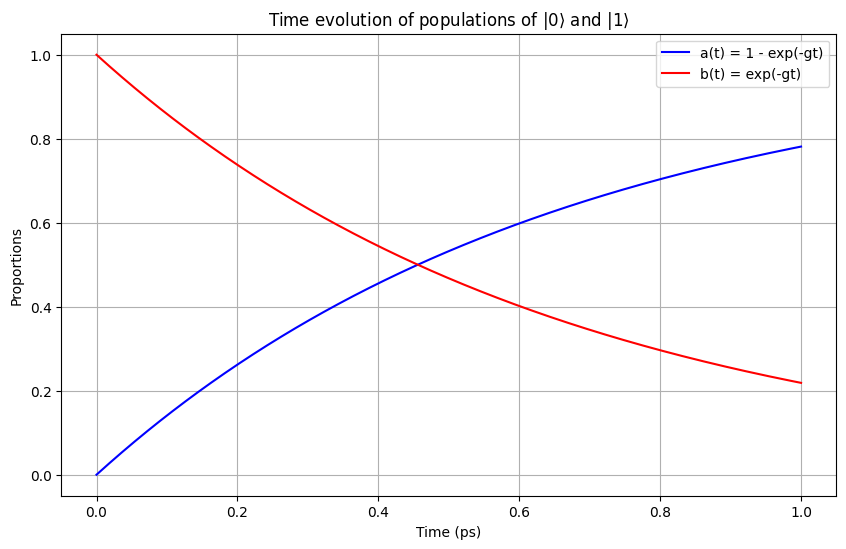

In [70]:
import matplotlib.pyplot as plt

# Time
etime = 1 # duration of time evolutio in nanoseconds

# Time range in picoseconds
t_ps = np.linspace(0, 1000*etime, 500) # 0 to 1000 ps with 500 points

# Convert time to nanoseconds for calculations
t_ns = t_ps * 1e-3

# Redefinition of a and b functions locally
g_ns = g * 1e-9

def a_ns(t):
    return 1 - np.exp(-g_ns * t)

def b_ns(t):
    return np.exp(-g_ns * t)

def h_ns(t): # Exact energy expectation value
    return (2*np.exp(-g_ns * t) - 1)*epsilon

# Calculate function values
a_values = a_ns(t_ns)
b_values = b_ns(t_ns)

# Plotting
plt.figure(figsize=(10, 6))
plt.plot(t_ns, a_values, label= r'a(t) = 1 - exp(-gt)', color = 'blue')
plt.plot(t_ns, b_values, label= r'b(t) = exp(-gt)', color = 'red')
plt.xlabel('Time (ps)')
plt.ylabel('Proportions')
plt.title(r'Time evolution of populations of $\vert 0 \rangle$ and $\vert 1 \rangle$')
plt.legend()
plt.grid(True)
plt.show()

In [75]:
'''
System and simulation parameters
'''

# Simulation parameters
etime = 1 # simulation duration in nanoseconds
print(f"Time: {etime} ns")

num_steps = 20 # number of steps
print(f"Steps: {num_steps}")

dt = etime/num_steps # magnitude of each simulation step in nanoseconds
print(f"Differential time: dt = {dt}")

# Coefficients
a = - (1 - np.sqrt(1 - (epsilon**2)*(dt**2)))/(dt**2)
b = - (1 - g_ns*dt/2 - np.sqrt(1 - g_ns*dt - (epsilon**2)*(dt**2)))/dt**2

print(f"Coefficient a: {a}")
print(f"Coefficient b: {b}")

k0 = 1 + a*dt**2 - 1j*epsilon*dt
k1 = 1 - g_ns*dt/2 + b*dt**2 + 1j*epsilon*dt
k2 = np.sqrt(g_ns*dt)

print(f"Coefficient k0: {k0}")
print(f"Coefficient k1: {k1}")
print(f"Coefficient k2: {k2}")

W = np.array([
    [k0, 0, 0, 0],
    [0, k1, k2, 0],
    [0, -k2, k1, 0],
    [0, 0, 0, k0]
    ])

print(f"Stinespring unitary: W = \n{W}")

# Unitarity test

print(f"W @ W.conj().T = \n{np.dot(W, W.conj().T)}")

Time: 1 ns
Steps: 20
Differential time: dt = 0.05
Coefficient a: -0.5003128912364206
Coefficient b: -0.8208338985043361
Coefficient k0: (0.998749217771909-0.05j)
Coefficient k1: (0.9599479152537391+0.05j)
Coefficient k2: 0.27568097504180444
Stinespring unitary: W = 
[[ 0.99874922-0.05j  0.        +0.j    0.        +0.j    0.        +0.j  ]
 [ 0.        +0.j    0.95994792+0.05j  0.27568098+0.j    0.        +0.j  ]
 [ 0.        +0.j   -0.27568098+0.j    0.95994792+0.05j  0.        +0.j  ]
 [ 0.        +0.j    0.        +0.j    0.        +0.j    0.99874922-0.05j]]
W @ W.conj().T = 
[[ 1.00000000e+00+0.j         0.00000000e+00+0.j
   0.00000000e+00+0.j         0.00000000e+00+0.j       ]
 [ 0.00000000e+00+0.j         1.00000000e+00+0.j
  -1.38210892e-17-0.0275681j  0.00000000e+00+0.j       ]
 [ 0.00000000e+00+0.j        -1.38210892e-17+0.0275681j
   1.00000000e+00+0.j         0.00000000e+00+0.j       ]
 [ 0.00000000e+00+0.j         0.00000000e+00+0.j
   0.00000000e+00+0.j         1.00000000

In [76]:
"Hamiltonian, Projections and Stinesprig unitary"

# Number of qubits in the system
num_qubits = 1

# Projections on the direction of computationa basis vectors
Proj_0 = SparsePauliOp.from_sparse_list([("II", [0,1], 1/2), ("ZI", [0,1], +1/2)], num_qubits = num_qubits + 1) # Proj_0
Proj_1 = SparsePauliOp.from_sparse_list([("II", [0,1], 1/2), ("ZI", [0,1], -1/2)], num_qubits= num_qubits + 1) # Proj_1

# Hamiltonian
from qiskit.quantum_info import SparsePauliOp
Hamiltonian = SparsePauliOp.from_sparse_list([("ZI", [0,1], -epsilon)], num_qubits = num_qubits + 1) # Hamiltoniano

# Stinespring unitary
from qiskit.circuit.library import UnitaryGate

W_gate = UnitaryGate(W, check_input = False, label="W")

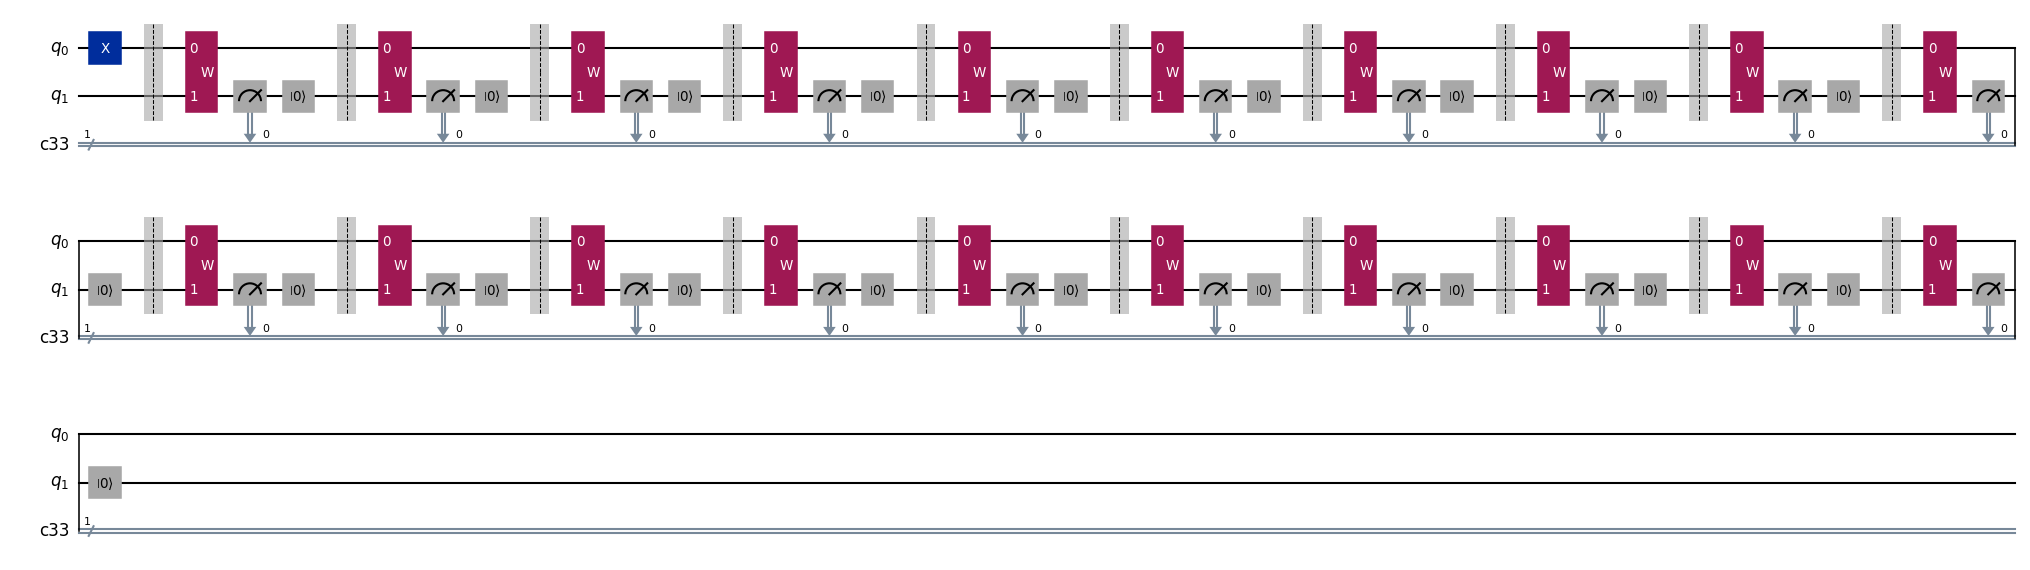

In [77]:
'''
Quantum circuit for simulation
'''

# Number of steps
num_steps = 20

# Quantum circuit
qr = QuantumRegister(2, name="q")
cr = ClassicalRegister(1)

qc = QuantumCircuit(qr, cr)

# Initial state
qc.x(qr[0])

# Evolution
qc_evolution = [qc.copy() for _ in range(num_steps + 1)]

for step in range(1,num_steps + 1):
    for _ in range(step):
        qc_evolution[step].barrier()
        qc_evolution[step].append(W_gate, [qr[0], qr[1]])
        qc_evolution[step].measure(qr[1], cr[0])
        qc_evolution[step].reset(qr[1])


#qcirc_evolucao[num_steps].measure_all()

qc_evolution[num_steps].draw(output="mpl", scale=0.750, fold=40)

In [83]:
from qiskit_aer.primitives import Estimator as AerEstimator

# Remoção de medidas no circuito para executar o AerEstimator
qc_evolution_simulation = [qc_evolution[step].remove_final_measurements(inplace=False) for step in range(num_steps)]

# Inicialização do Estimator
estimator = AerEstimator()

# Execução dos experimentos
population_0 = [0 for _ in range(num_steps)]
population_1 = [0 for _ in range(num_steps)]
for step in range(num_steps):
    job_0 = estimator.run(qc_evolution_simulation[step], Proj_0)
    result_0 = job_0.result()
    population_0[step] = result_0.values[0]
    job_1 = estimator.run(qc_evolution_simulation[step], Proj_1)
    result_1 = job_1.result()
    population_1[step] = result_1.values[0]

print(f"<Population 0>: {population_0}")
print(f"<Population 1>: {population_1}")

<Population 0>: [np.float64(0.0), np.float64(0.07421875), np.float64(0.13671875), np.float64(0.2138671875), np.float64(0.2802734375), np.float64(0.3212890625), np.float64(0.3662109375), np.float64(0.4208984375), np.float64(0.4716796875), np.float64(0.5), np.float64(0.5146484375), np.float64(0.609375), np.float64(0.619140625), np.float64(0.6552734375), np.float64(0.65625), np.float64(0.6884765625), np.float64(0.7109375), np.float64(0.7470703125), np.float64(0.75390625), np.float64(0.7763671875)]
<Population 1>: [np.float64(1.0), np.float64(0.9208984375), np.float64(0.861328125), np.float64(0.794921875), np.float64(0.740234375), np.float64(0.67578125), np.float64(0.6044921875), np.float64(0.58203125), np.float64(0.5498046875), np.float64(0.48828125), np.float64(0.435546875), np.float64(0.453125), np.float64(0.384765625), np.float64(0.3564453125), np.float64(0.33203125), np.float64(0.3095703125), np.float64(0.3056640625), np.float64(0.2421875), np.float64(0.2509765625), np.float64(0.20703

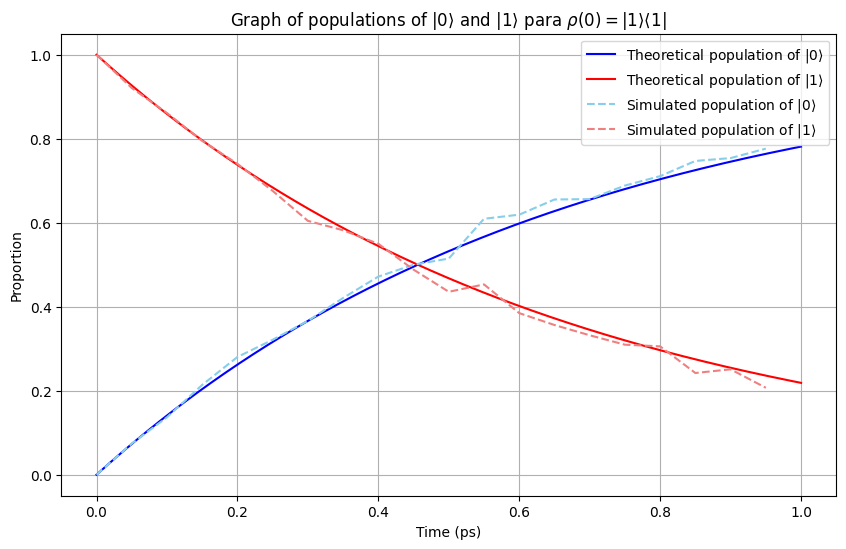

In [84]:
# Calculate function values
a_values = a_ns(t_ns)
b_values = b_ns(t_ns)

# Plotting
plt.figure(figsize=(10, 6))
plt.plot(t_ns, a_values, label= r'Theoretical population of $\vert 0 \rangle$', color = 'blue')
plt.plot(t_ns, b_values, label= r'Theoretical population of $\vert 1 \rangle$', color = 'red')

time_tic = [_*etime/num_steps for _ in range(num_steps)]

plt.plot(time_tic, population_0, label= r'Simulated population of $\vert 0 \rangle$', color = 'skyblue', ls='--')
plt.plot(time_tic, population_1, label= r'Simulated population of $\vert 1 \rangle$', color = 'lightcoral', ls='--')
plt.xlabel('Time (ps)')
plt.ylabel('Proportion')
plt.title(r'Graph of populations of $\vert 0 \rangle$ and $\vert 1 \rangle$ para $\rho(0) = \vert 1 \rangle\langle 1 \vert$')
plt.legend()
plt.grid(True)
plt.show()

### Energy time evolution

In [107]:
import time
from qiskit_aer.primitives import Estimator as AerEstimator

# Removing measuremente to execute the AerEstimator
qc_evolution_simulation = [qc_evolution[step].remove_final_measurements(inplace=False) for step in range(num_steps + 1)]

# Estimator initialization
shots = 10**6  # precision = 1/sqrt(shots)
estimator = AerEstimator(run_options={"shots": shots})

start_time = time.time()

# Experiments
energies = [0 for step in range(num_steps + 1)]
for step in range(num_steps + 1):
    job_0 = estimator.run(qc_evolution_simulation[step], Hamiltonian)
    result_0 = job_0.result()
    energies[step] = result_0.values[0]

final_time = time.time()

print(f"<Energias>: {energies}")
print(f"Duração: {final_time - start_time}")

<Energias>: [np.float64(1.0), np.float64(0.84853), np.float64(0.706468), np.float64(0.578722), np.float64(0.45796), np.float64(0.345994), np.float64(0.246388), np.float64(0.149826), np.float64(0.063936), np.float64(-0.019332), np.float64(-0.09272), np.float64(-0.162038), np.float64(-0.224924), np.float64(-0.283), np.float64(-0.339156), np.float64(-0.38916), np.float64(-0.436222), np.float64(-0.477198), np.float64(-0.519008), np.float64(-0.554388), np.float64(-0.588358)]
Duração: 758.3197863101959


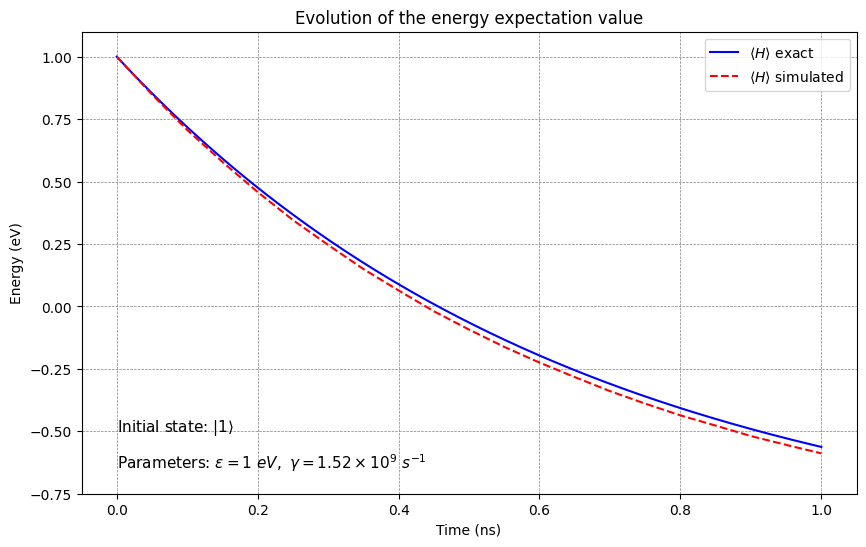

In [108]:
import matplotlib.pyplot as plt
import numpy as np

# Plotting
plt.figure(figsize=(10, 6))

time_tic = np.array([_/num_steps for _ in range(num_steps + 1)])

h_values = h_ns(t_ns)

plt.plot(t_ns, h_values, label= r'$\left\langle H \right\rangle$ exact', color = 'blue')
plt.plot(time_tic, energies, label= r'$\left\langle H \right\rangle$ simulated', color = 'red', ls='--')

plt.xlabel('Time (ns)')
plt.ylabel('Energy (eV)')
plt.ylim(-0.75, 1.1)

plt.grid(color='gray', linestyle='--', linewidth=0.5)
plt.title(r'Evolution of the energy expectation value')
plt.text(0.0, -0.5, r'Initial state: $\vert 1 \rangle$', fontsize=11, color="black")
plt.text(0.0, -0.65, r'Parameters: $\epsilon = 1\ eV,\ \gamma = 1.52\times 10^9\ s^{-1}$', fontsize=11, color="black")
plt.legend()
plt.grid(True)
plt.show()

In [96]:
# Get the figure object from the quantum circuit's draw method
fig = qc_evolution[num_steps].draw(output="mpl", scale=0.750, fold=40)

# Save the figure to a file
fig.savefig('SQO_StatePreparation.png', bbox_inches='tight', dpi=300)

print("Circuit diagram saved: 'SQO_StatePreparation.png'!")

Circuit diagram saved: 'SQO_StatePreparation.png'!
